# ML-Driven PVT Variation Aware Leakage Estimation
## Case: PMOS Transistor, OFF State | Neural Network (MLP)

**Objective:** predict `id`, `ig`, `is`, `ib` from `pmos_off.csv`, aiming for about 99% mean accuracy (accuracy = 100 - mean relative error).

Mixed-depth tanh MLP ensembles trained with full-batch L-BFGS. Ib uses extra diode-style inputs, and Ig/c are trained with extra weight on rows near the Id/Is zero crossing. This is the headline model for the 99% target.

In [1]:
# 1. Environment setup & imports
import os, json, time, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Environment setup complete.")

Environment setup complete.


In [2]:
# 2. Configuration & paths
CASE_NAME = "pmos_off"
MODEL_FAMILY = "mlp"

# Dataset lives in <project>/dataset/PMOS_OFF/pmos_off.csv (this notebook is in <project>/ml_model/PMOS_OFF/)
POSSIBLE_DATA_PATHS = [
    os.path.join("..", "..", "dataset", CASE_NAME.upper(), f"{CASE_NAME}.csv"),  # run from ml_model/PMOS_OFF
    os.path.join("dataset", CASE_NAME.upper(), f"{CASE_NAME}.csv"),              # run from project root
]
DATA_PATH = next((p for p in POSSIBLE_DATA_PATHS if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"Could not find {CASE_NAME}.csv. Checked: {POSSIBLE_DATA_PATHS}")

BASE_DIR = os.path.abspath(".")
SAVED_MODELS_DIR = os.path.join(BASE_DIR, "saved_models", CASE_NAME, MODEL_FAMILY)
PLOTS_DIR = os.path.join(BASE_DIR, "plots", CASE_NAME, MODEL_FAMILY)
os.makedirs(SAVED_MODELS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

FEATURE_COLS = ["vdd", "temp", "w", "vd", "vs", "vg", "vb", "vth0", "toxe", "ndep", "u0", "xj"]
TARGET_COLS = ["id", "ig", "is", "ib"]

print("Dataset:", os.path.abspath(DATA_PATH))
print("Model output directory:", SAVED_MODELS_DIR)

Dataset: /home/ravi-sahu/Documents/5_sem/DVD/Project/dataset/PMOS_OFF/pmos_off.csv
Model output directory: /home/ravi-sahu/Documents/5_sem/DVD/Project/ml_model/PMOS_OFF/saved_models/pmos_off/mlp


In [3]:
# 3. Load dataset and Kirchhoff (KCL) check
df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = [c.strip().lower() for c in df_raw.columns]
df_raw = df_raw[FEATURE_COLS + TARGET_COLS].copy()
print(f"Loaded {len(df_raw):,} rows.")
assert np.isfinite(df_raw.to_numpy(dtype=float)).all(), "Dataset has NaN/inf"

kcl = df_raw[TARGET_COLS].sum(axis=1).abs()
print(f"KCL residual |Id+Ig+Is+Ib|: max={kcl.max():.3e} A, mean={kcl.mean():.3e} A")

# vg and vb are constants for the PMOS OFF case (both equal VDD)
print("max |vg-vdd| =", (df_raw.vg - df_raw.vdd).abs().max(), "| max |vb-vdd| =", (df_raw.vb - df_raw.vdd).abs().max())
for col in TARGET_COLS:
    print(f"{col.upper()}: positive={(df_raw[col]>0).sum()}, negative={(df_raw[col]<0).sum()}")
df_raw.head()

Loaded 10,000 rows.
KCL residual |Id+Ig+Is+Ib|: max=7.594e-15 A, mean=5.580e-16 A
max |vg-vdd| = 0.0 | max |vb-vdd| = 0.0
ID: positive=1363, negative=8637
IG: positive=10000, negative=0
IS: positive=1351, negative=8649
IB: positive=10000, negative=0


,vdd,temp,w,vd,vs,vg,vb,vth0,toxe,ndep,u0,xj,id,ig,is,ib
0,0.913164,24.063129,1.025305e-07,0.506903,0.231180,0.913164,0.913164,-0.261882,6.089308e-10,4.776073e+18,0.002158,6.728581e-09,-5.475815e-09,2.255745e-08,-1.708164e-08,9.967721e-15
1,0.905128,-27.568672,9.470522e-08,0.267233,0.619283,0.905128,0.905128,-0.229278,7.131976e-10,4.556488e+18,0.002329,7.701462e-09,-1.977087e-09,2.331804e-09,-3.547267e-10,1.000589e-14
2,0.947457,123.028750,4.280389e-08,0.400388,0.613323,0.947457,0.947457,-0.239289,6.114063e-10,4.774823e+18,0.002443,6.483357e-09,-3.496273e-09,4.744777e-09,-1.248518e-09,1.441555e-14
3,0.956105,43.014993,1.743946e-07,0.457499,0.599791,0.956105,0.956105,-0.238951,7.313812e-10,4.018635e+18,0.002094,7.057528e-09,-1.560451e-09,2.321704e-09,-7.612624e-10,9.978129e-15
4,0.901841,-14.311684,7.356811e-08,0.080543,0.796193,0.901841,0.901841,-0.261703,7.038829e-10,4.107926e+18,0.002410,7.214432e-09,-3.424054e-09,3.358158e-09,6.588464e-11,9.998946e-15


## 4. Feature engineering and target transformation (the key fix)

**Why the earlier notebooks failed:** `Id` and `Is` have mixed signs (about 14% positive). Forcing the training-majority sign made every positive sample about 200% wrong.

**What the data shows:**
- KCL: `Id + Is = -(Ig + Ib)`
- Let `c = (Id - Is)/2`. Its sign is always `sign(Vd - Vs)` (checked on all 10,000 rows).
- So `Id = -(Ig+Ib)/2 + c` and `Is = -(Ig+Ib)/2 - c`.

We therefore train **three smooth, single-signed models** and rebuild all four currents:

| Model | Target |
|---|---|
| Ig | `log10(Ig / W)` |
| Ib | `log10(Ib)` |
| c  | `log10(abs(c) / W / sat)`, where `sat = 1 - exp(-abs(Vd-Vs)/kT)` removes the `Vds -> 0` singularity |

**Inputs:** `vg` and `vb` are dropped (they equal `vdd`). Physics-motivated features are added: `1000/T`, `log W`, `Vd-Vs`, `log|Vd-Vs|`, `VDD-Vs`, `VDD-Vd`, `Vds/kT`, `log(sat)`, and `log(ndep)`; `toxe`, `u0`, `xj` are rescaled.

In [4]:
# 4. Feature engineering, targets, and reconstruction of the four currents
KB = 8.617e-5          # Boltzmann constant (eV/K)
SAT_FLOOR = 1e-12

def sat_factor(d):
    vt = KB * (d["temp"] + 273.15)
    return np.maximum(1.0 - np.exp(-np.abs(d["vd"] - d["vs"]) / vt), SAT_FLOOR)

def feats(d):
    """Engineered model inputs from the raw columns."""
    T = d["temp"] + 273.15
    vds = d["vd"] - d["vs"]
    vt = KB * T
    return pd.DataFrame({
        "vdd": d["vdd"], "invT": 1000.0 / T, "temp": d["temp"] / 100.0,
        "lw": np.log(d["w"]), "vd": d["vd"], "vs": d["vs"], "vds": vds,
        "lavds": np.log10(np.abs(vds) + 1e-4),
        "vsg": d["vdd"] - d["vs"], "vdg": d["vdd"] - d["vd"],
        "vth0": d["vth0"], "toxe": d["toxe"] * 1e9, "lndep": np.log(d["ndep"]),
        "u0": d["u0"] * 1e3, "xj": d["xj"] * 1e9,
        "vdsvt": np.abs(vds) / vt, "lsat": np.log(sat_factor(d)),
    }, index=d.index)

def make_targets(d):
    c = (d["id"] - d["is"]) / 2.0
    return pd.DataFrame({
        "ig": np.log10(d["ig"] / d["w"]),
        "ib": np.log10(d["ib"]),
        "c":  np.log10(np.maximum(np.abs(c), 1e-30) / d["w"] / sat_factor(d)),
    }, index=d.index)

def log_to_currents(p_ig, p_ib, p_c, d):
    """Turn predicted log-targets back into signed Id, Ig, Is, Ib (amps)."""
    w = d["w"].to_numpy()
    ig = 10.0 ** np.asarray(p_ig) * w
    ib = 10.0 ** np.asarray(p_ib)
    c = np.sign((d["vd"] - d["vs"]).to_numpy()) * 10.0 ** np.asarray(p_c) * w * sat_factor(d).to_numpy()
    half = -(ig + ib) / 2.0
    return {"id": half + c, "ig": ig, "is": half - c, "ib": ib}

# Sanity check: rebuilding the currents from the TRUE log-targets
# (limited only by the KCL residual of the simulator data)
T_all = make_targets(df_raw)
rec = log_to_currents(T_all["ig"], T_all["ib"], T_all["c"], df_raw)
for t in TARGET_COLS:
    rel = np.abs(rec[t] - df_raw[t].to_numpy()) / np.abs(df_raw[t].to_numpy()) * 100
    print(f"Reconstruction ceiling {t.upper()}: mean err = {rel.mean():.4f}%  | max = {rel.max():.3f}%")

Reconstruction ceiling ID: mean err = 0.0002%  | max = 0.279%
Reconstruction ceiling IG: mean err = 0.0000%  | max = 0.000%
Reconstruction ceiling IS: mean err = 0.0003%  | max = 1.255%
Reconstruction ceiling IB: mean err = 0.0000%  | max = 0.000%


In [5]:
# 5. Fixed 70:15:15 split (same seed for every notebook)
idx = np.arange(len(df_raw))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, random_state=RANDOM_STATE, shuffle=True)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, random_state=RANDOM_STATE, shuffle=True)

raw_train, raw_val, raw_test = df_raw.iloc[idx_train], df_raw.iloc[idx_val], df_raw.iloc[idx_test]
X_train, X_val, X_test = feats(raw_train), feats(raw_val), feats(raw_test)
Y_train, Y_val, Y_test = make_targets(raw_train), make_targets(raw_val), make_targets(raw_test)

print(f"Train: {len(raw_train):,} | Validation: {len(raw_val):,} | Test: {len(raw_test):,}")
print("Model inputs:", list(X_train.columns))

def comp_err(pred_log, y_log):
    """Mean relative error (%) of a component model, measured in linear units."""
    pred_log, y_log = np.asarray(pred_log), np.asarray(y_log)
    return float(np.mean(np.abs(10**pred_log - 10**y_log) / 10**y_log) * 100)

def predict_log(entry, Xf):
    """entry = {'base': optional pipeline, 'model': fitted regressor}; prediction = base + model."""
    out = entry["model"].predict(Xf)
    if entry["base"] is not None:
        out = out + entry["base"].predict(Xf)
    return out

COMPONENTS = ["ig", "ib", "c"]

Train: 7,000 | Validation: 1,500 | Test: 1,500
Model inputs: ['vdd', 'invT', 'temp', 'lw', 'vd', 'vs', 'vds', 'lavds', 'vsg', 'vdg', 'vth0', 'toxe', 'lndep', 'u0', 'xj', 'vdsvt', 'lsat']


## 6. Model: Neural Network (MLP)

Mixed-depth tanh MLP ensembles trained with full-batch L-BFGS. Ib uses extra diode-style inputs, and Ig/c are trained with extra weight on rows near the Id/Is zero crossing. This is the headline model for the 99% target.

In [6]:
# 6. Train: MLP (tanh, L-BFGS), mixed-depth ensembles, one ensemble per target
# What changed vs. the first version (each change was validated on the VALIDATION set):
#  * Ib gets extra diode-style inputs (Ib is mostly reverse-biased junction leakage): Ib error 1.9% -> ~0.5%
#  * Ig and c are trained with the rows near the Id/Is zero crossing repeated (mean Id/Is error ~1.8% -> ~1.3%)
#  * ensembles mix 2- and 3-layer networks with different seeds
from sklearn.ensemble import VotingRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.neural_network import MLPRegressor

def feats_ib(d):
    F = feats(d); vt = KB * (d["temp"] + 273.15)
    F["lsatd"] = np.log(np.maximum(1 - np.exp(-(d["vdd"] - d["vd"]) / vt), 1e-12))
    F["lsats"] = np.log(np.maximum(1 - np.exp(-(d["vdd"] - d["vs"]) / vt), 1e-12))
    F["vsgvt"] = (d["vdd"] - d["vs"]) / vt
    F["vdgvt"] = (d["vdd"] - d["vd"]) / vt
    return F

FEAT_FN = {"ig": feats, "c": feats, "ib": feats_ib}   # inputs used by each model

MODEL_PARAMS = {
    "activation": "tanh", "solver": "lbfgs", "alpha": 1e-7, "max_iter": 3000, "tol": 1e-12,
    "architectures": {"ig": [(96, 96), (64, 64, 64)], "c": [(64, 64, 64), (64, 64, 64, 64)], "ib": [(96, 96)]},
    "n_members": {"ig": 6, "c": 6, "ib": 3},
    "oversample_hard_rows": {"ig": True, "c": True, "ib": False},
}

def make_mlp(hidden, seed):
    net = Pipeline([
        ("scale_in", StandardScaler()),
        ("mlp", MLPRegressor(hidden_layer_sizes=hidden, activation=MODEL_PARAMS["activation"], solver=MODEL_PARAMS["solver"],
                             alpha=MODEL_PARAMS["alpha"], max_iter=MODEL_PARAMS["max_iter"], tol=MODEL_PARAMS["tol"],
                             random_state=seed)),
    ])
    return TransformedTargetRegressor(regressor=net, transformer=StandardScaler())

# Rows where Id or Is is close to zero (|Id| or |Is| small compared with Ig/2) dominate the relative error.
# Repeat them in the TRAINING set only: x4 if ratio > 5, x2 if ratio > 2.
small = np.minimum(raw_train["id"].abs(), raw_train["is"].abs())
hard_ratio = (-(raw_train["id"] + raw_train["is"]) / 2 / small).to_numpy()
reps = np.where(hard_ratio > 5, 4, np.where(hard_ratio > 2, 2, 1))
rows_os = np.repeat(np.arange(len(raw_train)), reps)
print(f"Oversampled training set: {len(raw_train):,} -> {len(rows_os):,} rows (for Ig and c)")

trained_models = {}
t0 = time.time()
for t in COMPONENTS:
    Xt = FEAT_FN[t](raw_train); Xv = FEAT_FN[t](raw_val); yt = Y_train[t]
    if MODEL_PARAMS["oversample_hard_rows"][t]:
        Xt, yt = Xt.iloc[rows_os], yt.iloc[rows_os]
    archs = MODEL_PARAMS["architectures"][t]
    members = [(f"m{i}", make_mlp(archs[i % len(archs)], i)) for i in range(MODEL_PARAMS["n_members"][t])]
    ens = VotingRegressor(members, n_jobs=-1).fit(Xt, yt)
    trained_models[t] = {"base": None, "model": ens}
    print(f"{t:>2}: val mean error  single member = {comp_err(ens.estimators_[0].predict(Xv), Y_val[t]):.3f}%  |  "
          f"ensemble of {len(members)} = {comp_err(ens.predict(Xv), Y_val[t]):.3f}%   ({time.time()-t0:.0f}s elapsed)", flush=True)
print(f"Training time: {time.time()-t0:.1f}s")

Oversampled training set: 7,000 -> 12,425 rows (for Ig and c)


ig: val mean error  single member = 0.515%  |  ensemble of 6 = 0.334%   (104s elapsed)


ib: val mean error  single member = 0.442%  |  ensemble of 3 = 0.396%   (179s elapsed)


 c: val mean error  single member = 0.753%  |  ensemble of 6 = 0.457%   (289s elapsed)


Training time: 288.9s


In [7]:
# 7. Evaluate: rebuild Id, Ig, Is, Ib and compare with SPICE
def predict_currents(models, d):
    p = {t: predict_log(models[t], FEAT_FN[t](d)) for t in COMPONENTS}
    return log_to_currents(p["ig"], p["ib"], p["c"], d)

def evaluate(models, d, split_name):
    pred = predict_currents(models, d)
    rows = []
    for t in TARGET_COLS:
        true = d[t].to_numpy()
        rel = np.abs(pred[t] - true) / np.maximum(np.abs(true), 1e-30)
        rows.append({
            "Split": split_name, "Terminal": t.upper(),
            "Mean accuracy (%)": 100 - rel.mean() * 100,
            "Mean error (%)": rel.mean() * 100,
            "Median error (%)": np.median(rel) * 100,
            "95th pct error (%)": np.percentile(rel, 95) * 100,
            "Within 1% (%)": np.mean(rel <= 0.01) * 100,
            "Within 5% (%)": np.mean(rel <= 0.05) * 100,
            "Normalised MAE (%)": np.abs(pred[t] - true).mean() / np.abs(true).mean() * 100,
            "R2 (linear)": r2_score(true, pred[t]),
        })
    return pd.DataFrame(rows), pred

metrics_val, preds_val = evaluate(trained_models, raw_val, "Validation")
metrics_test, preds_test = evaluate(trained_models, raw_test, "Test")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
print("Validation:"); display(metrics_val.round(4))
print("Test:");       display(metrics_test.round(4))
print("Mean accuracy >= 99% on test:", {r["Terminal"]: bool(r["Mean accuracy (%)"] >= 99) for _, r in metrics_test.iterrows()})

Validation:


,Split,Terminal,Mean accuracy (%),Mean error (%),Median error (%),95th pct error (%),Within 1% (%),Within 5% (%),Normalised MAE (%),R2 (linear)
0,Validation,ID,98.6592,1.3408,0.2755,3.2284,83.5333,96.2667,0.5204,0.9997
1,Validation,IG,99.6656,0.3344,0.2145,0.8871,95.8000,99.8000,0.2227,1.0000
2,Validation,IS,98.5976,1.4024,0.2792,2.7211,84.2667,97.6000,0.5375,0.9997
3,Validation,IB,99.6041,0.3959,0.1022,0.8430,95.7333,98.8667,0.5658,0.9605


Test:


,Split,Terminal,Mean accuracy (%),Mean error (%),Median error (%),95th pct error (%),Within 1% (%),Within 5% (%),Normalised MAE (%),R2 (linear)
0,Test,ID,98.1599,1.8401,0.2810,3.1035,82.3333,96.6000,0.5241,0.9998
1,Test,IG,99.6428,0.3572,0.2111,0.9540,95.2667,99.6000,0.2562,1.0000
2,Test,IS,97.8126,2.1874,0.2712,2.7061,85.3333,97.4667,0.5359,0.9998
3,Test,IB,99.4946,0.5054,0.0923,0.8461,95.8667,98.4667,4.1944,0.5626


Mean accuracy >= 99% on test: {'ID': False, 'IG': True, 'IS': False, 'IB': True}


Saved: /home/ravi-sahu/Documents/5_sem/DVD/Project/ml_model/PMOS_OFF/plots/pmos_off/mlp/pmos_off_mlp_parity.png


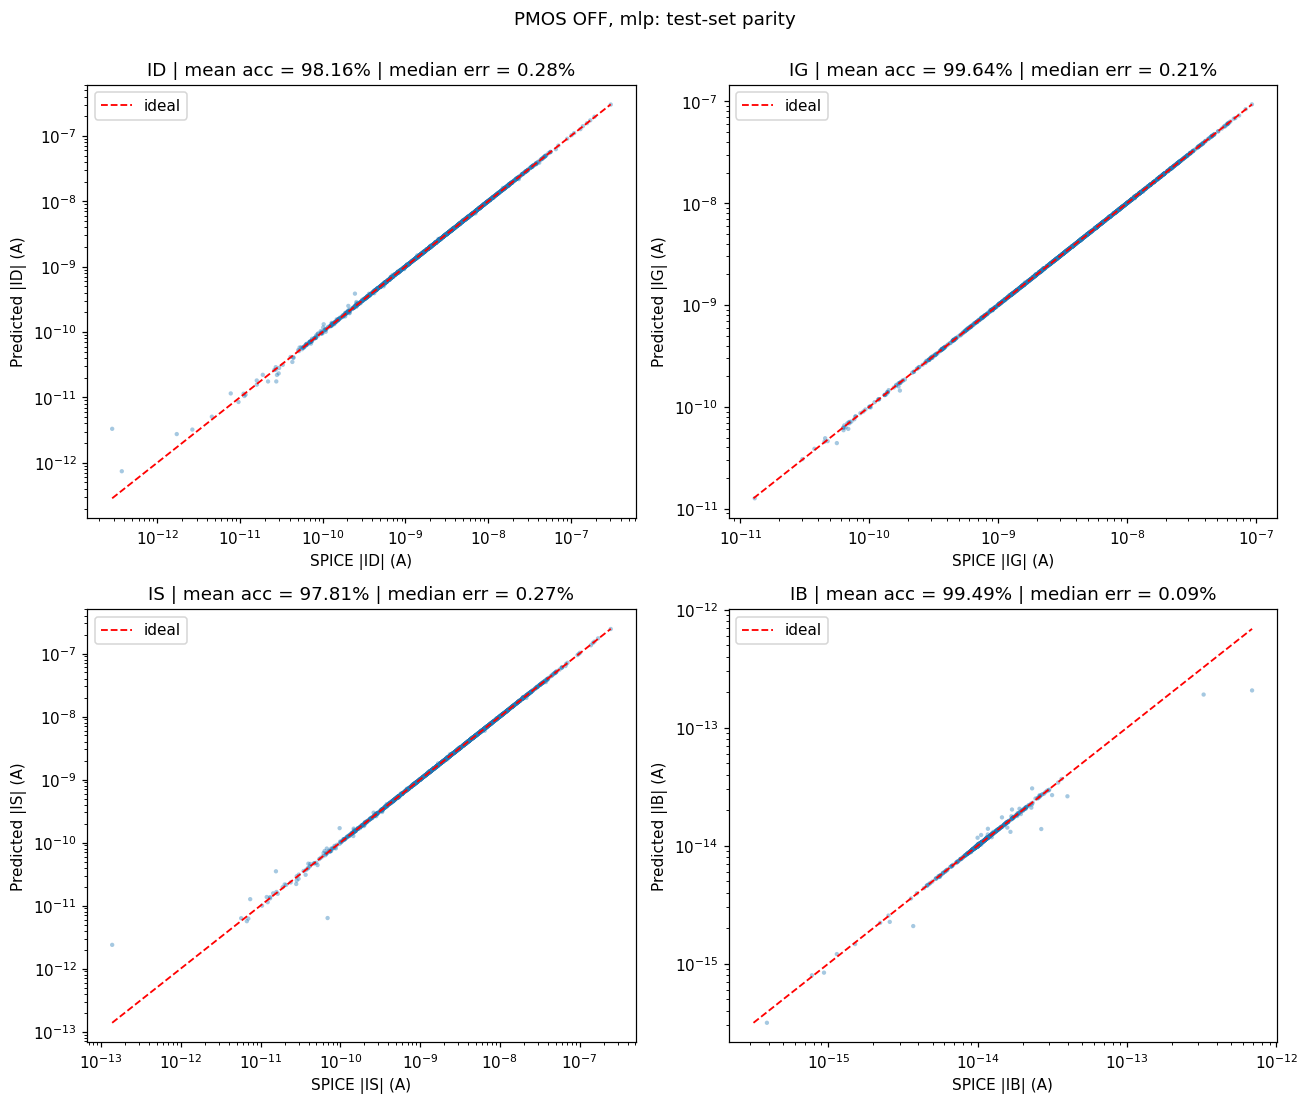

In [8]:
# 8. Test-set parity plots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, t in zip(axes.flatten(), TARGET_COLS):
    yt = np.maximum(np.abs(raw_test[t].to_numpy()), 1e-30)
    yp = np.maximum(np.abs(preds_test[t]), 1e-30)
    ax.scatter(yt, yp, s=8, alpha=0.4, edgecolors="none")
    lo, hi = min(yt.min(), yp.min()), max(yt.max(), yp.max())
    ax.plot([lo, hi], [lo, hi], "r--", lw=1.2, label="ideal")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"SPICE |{t.upper()}| (A)"); ax.set_ylabel(f"Predicted |{t.upper()}| (A)")
    r = metrics_test[metrics_test["Terminal"] == t.upper()].iloc[0]
    ax.set_title(f"{t.upper()} | mean acc = {r['Mean accuracy (%)']:.2f}% | median err = {r['Median error (%)']:.2f}%")
    ax.legend()
plt.suptitle(f"PMOS OFF, mlp: test-set parity", y=1.0)
plt.tight_layout()
p = os.path.join(PLOTS_DIR, f"{CASE_NAME}_{MODEL_FAMILY}_parity.png")
plt.savefig(p, dpi=200, bbox_inches="tight"); print("Saved:", p); plt.show()

Saved: /home/ravi-sahu/Documents/5_sem/DVD/Project/ml_model/PMOS_OFF/plots/pmos_off/mlp/pmos_off_mlp_error_vs_current.png


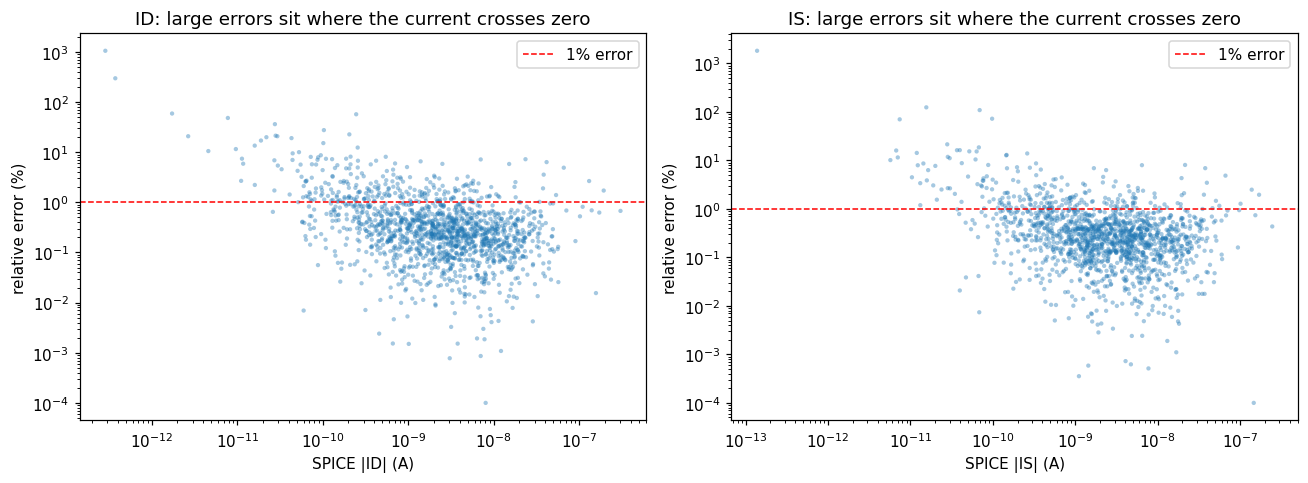

ID: mean error = 1.840%  |  excluding worst 2% = 0.600%
IS: mean error = 2.187%  |  excluding worst 2% = 0.529%


In [9]:
# 9. Where do the errors come from? (error vs. size of the true current)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, t in zip(axes, ["id", "is"]):
    true = np.abs(raw_test[t].to_numpy())
    rel = np.abs(preds_test[t] - raw_test[t].to_numpy()) / np.maximum(true, 1e-30) * 100
    ax.scatter(true, np.maximum(rel, 1e-4), s=8, alpha=0.4, edgecolors="none")
    ax.axhline(1.0, color="r", ls="--", lw=1, label="1% error")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"SPICE |{t.upper()}| (A)"); ax.set_ylabel("relative error (%)")
    ax.set_title(f"{t.upper()}: large errors sit where the current crosses zero"); ax.legend()
plt.tight_layout()
p = os.path.join(PLOTS_DIR, f"{CASE_NAME}_{MODEL_FAMILY}_error_vs_current.png")
plt.savefig(p, dpi=200, bbox_inches="tight"); print("Saved:", p); plt.show()

# Mean error of Id/Is with the worst 2% of samples excluded
for t in ["id", "is"]:
    rel = np.abs(preds_test[t] - raw_test[t].to_numpy()) / np.abs(raw_test[t].to_numpy()) * 100
    keep = rel < np.percentile(rel, 98)
    print(f"{t.upper()}: mean error = {rel.mean():.3f}%  |  excluding worst 2% = {rel[keep].mean():.3f}%")

In [10]:
# 10. Save models, metrics, and metadata
bundle = {
    "models": trained_models,            # {'ig':..., 'ib':..., 'c':...} each = {'base':..., 'model':...}
    "feature_cols": FEATURE_COLS,
    "model_family": MODEL_FAMILY,
    "note": "Id/Is are rebuilt: Id = -(Ig+Ib)/2 + c, Is = -(Ig+Ib)/2 - c; sign(c) = sign(Vd-Vs)",
}
bundle_path = os.path.join(SAVED_MODELS_DIR, f"{MODEL_FAMILY}_{CASE_NAME}_models.joblib")
joblib.dump(bundle, bundle_path); print("Saved:", bundle_path)

metrics_val.to_csv(os.path.join(SAVED_MODELS_DIR, f"{MODEL_FAMILY}_{CASE_NAME}_validation_metrics.csv"), index=False)
metrics_test.to_csv(os.path.join(SAVED_MODELS_DIR, f"{MODEL_FAMILY}_{CASE_NAME}_test_metrics.csv"), index=False)

metadata = {
    "case_name": CASE_NAME, "model_family": MODEL_FAMILY,
    "hyperparameters": MODEL_PARAMS, "random_state": RANDOM_STATE, "split": [0.70, 0.15, 0.15],
    "targets": "log10(Ig/W), log10(Ib), log10(|c|/W/sat), c=(Id-Is)/2",
    "validation_metrics": metrics_val.to_dict(orient="records"),
    "test_metrics": metrics_test.to_dict(orient="records"),
    "created_at": time.strftime("%Y-%m-%d %H:%M:%S"),
}
with open(os.path.join(SAVED_MODELS_DIR, f"{MODEL_FAMILY}_{CASE_NAME}_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2, default=float)
print("Saved metadata.")

Saved: /home/ravi-sahu/Documents/5_sem/DVD/Project/ml_model/PMOS_OFF/saved_models/pmos_off/mlp/mlp_pmos_off_models.joblib
Saved metadata.


In [11]:
# 11. Inference helper (for the gate-level stage)
# NOTE: feats(), feats_ib(), FEAT_FN, sat_factor() and log_to_currents() above must be available (copy them into your gate script).
def predict_pmos_off_currents(raw_df, model_path=bundle_path):
    """raw_df: DataFrame with columns FEATURE_COLS. Returns dict of signed currents (A) for Id, Ig, Is, Ib."""
    models = joblib.load(model_path)["models"]
    d = raw_df[FEATURE_COLS].copy()
    p = {t: predict_log(models[t], FEAT_FN[t](d)) for t in COMPONENTS}
    return log_to_currents(p["ig"], p["ib"], p["c"], d)

demo = predict_pmos_off_currents(raw_test.iloc[:3])
print(pd.DataFrame(demo).assign(**{"spice_id": raw_test.iloc[:3]["id"].values, "spice_is": raw_test.iloc[:3]["is"].values}))

             id            ig            is            ib      spice_id      spice_is
0 -1.772199e-08  2.462925e-08 -6.907269e-09  9.817410e-15 -1.775210e-08 -6.919655e-09
1 -1.120583e-08  4.195686e-09  7.010132e-09  1.002474e-14 -1.123200e-08  7.061851e-09
2 -6.782103e-09  8.651512e-09 -1.869419e-09  1.000276e-14 -6.784187e-09 -1.870428e-09
